# Week 1: Data Collection & Exploratory Data Analysis (EDA)

**Project:** AI-Based Resume Screening and Candidate Shortlisting System  
**Program:** B.Tech Information Technology Project (Under Guidance of HCL Tech)  
**Milestone:** Week 1 of 9  
**Status:** Completed  

---

## 1. Objectives and Scope
1. Synthesize a realistic dataset of 1,000+ candidate resumes across 5 technical job profiles.
2. Introduce controlled data imperfections (missing values, duplicates, outliers) to validate downstream cleaning pipelines.
3. Perform preliminary Exploratory Data Analysis (EDA) on candidate qualifications, experience, and shortlisting outcomes.
4. Establish baseline data schema and descriptive statistics for feature engineering.

---

## 2. Data Collection and Generation

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Set plotting aesthetics
plt.style.use('dark_background')
sns.set_palette('husl')

print('Core libraries imported successfully.')

Core libraries imported successfully.


In [2]:
# Load generator function from src/dataset_generator.py
sys.path.append(os.path.join('..', 'src'))
from dataset_generator import make_dataset

# load existing raw dataset or generate if missing
csv_path = os.path.join('..', 'data', 'raw_resumes.csv')
if os.path.exists(csv_path):
    df_raw = pd.read_csv(csv_path)
    print(f'Loaded existing dataset from {csv_path}')
else:
    df_raw = make_dataset(n=1000)
    os.makedirs(os.path.join('..', 'data'), exist_ok=True)
    df_raw.to_csv(csv_path, index=False)
    print(f'Generated new raw dataset and saved to {csv_path}')

print(f'Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns')


Loaded existing dataset from ..\data\raw_resumes.csv
Dataset Dimensions: 1020 rows, 9 columns


### Design Rationale for Synthetic Dataset

| Feature / Parameter | Configuration | Engineering Rationale |
|---|---|---|
| Sample Size | 1,020 rows | Appropriate sample size for cross-validation and feature scaling tests. |
| Target Roles | 5 profiles | Covers common recruitment tracks: Data Scientist, ML Engineer, Python Dev, Web Dev, Analyst. |
| Missing Values | ~3% on numeric columns | Simulates candidate omissions in online application forms. |
| Duplicate Records | ~2% | Emulates duplicate application submissions across job portals. |
| Outlier Records | 8 rows | Tests data preprocessing boundary limits (e.g., extreme experience or CGPA values). |
| Label Logic | Multi-attribute scoring | Reflects realistic qualification benchmarks with controlled stochastic noise. |

## 3. Dataset Overview and Schema Inspection

In [3]:
df = pd.read_csv('../data/raw_resumes.csv')
print('=== DATASET DIMENSIONS ===')
print(f'Total Rows    : {len(df):,}')
print(f'Total Columns : {len(df.columns)}')
print('\n=== FIRST 5 RECORDS ===')
df.head()

=== DATASET DIMENSIONS ===
Total Rows    : 1,020
Total Columns : 9

=== FIRST 5 RECORDS ===


,Candidate_ID,Resume_Text,Skills,Experience_Years,Education,CGPA,Projects_Count,Job_Role,Shortlisted
0,CID_1001,Passionate Data Scientist professional with B....,"Video Editing, sql, machine learning",1.7,B.Tech,6.96,4,Data Scientist,0
1,CID_1002,Passionate Software Engineer professional with...,"c++, algorithms, sql, oop, java, data structur...",6.4,B.Tech,9.15,7,Software Engineer,1
2,CID_1003,Passionate Python Developer professional with ...,"rest apis, django, docker, sql, flask, python,...",8.1,B.Tech,9.18,7,Python Developer,1
3,CID_1004,Passionate Software Engineer professional with...,"java, algorithms, c++, sql, system design, git",8.5,MCA,9.49,6,Software Engineer,1
4,CID_1005,Passionate Data Analyst professional with BCA ...,"tableau, Salesforce, SEO, dashboard",2.6,BCA,8.38,4,Data Analyst,0


In [4]:
# Column schema, data types, and null value analysis
print('=== COLUMN SCHEMA & INTEGRITY ===')
info_df = pd.DataFrame({
    'Column': df.columns,
    'Dtype': [str(t) for t in df.dtypes],
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Null Ratio (%)': [f"{round(df[c].isnull().mean()*100, 2)}%" for c in df.columns]
})
print(info_df.to_string(index=False))

=== COLUMN SCHEMA & INTEGRITY ===
          Column   Dtype  Non-Null Count  Null Count Null Ratio (%)
    Candidate_ID  object            1020           0           0.0%
     Resume_Text  object            1020           0           0.0%
          Skills  object             990          30          2.94%
Experience_Years float64             990          30          2.94%
       Education  object             990          30          2.94%
            CGPA float64             989          31          3.04%
  Projects_Count   int64            1020           0           0.0%
        Job_Role  object            1020           0           0.0%
     Shortlisted   int64            1020           0           0.0%


In [5]:
print('=== DESCRIPTIVE STATISTICS (NUMERICAL) ===')
df.describe().round(2)

=== DESCRIPTIVE STATISTICS (NUMERICAL) ===


,Experience_Years,CGPA,Projects_Count,Shortlisted
count,990.0,989.00,1020.00,1020.00
mean,4.2,7.85,3.75,0.44
std,2.6,1.10,2.03,0.50
min,-1.0,5.51,1.00,0.00
25%,2.3,7.10,2.00,0.00
50%,3.7,7.92,4.00,0.00
75%,5.8,8.61,5.00,1.00
max,28.0,14.50,25.00,1.00


## 4. Data Quality and Anomaly Inspection

In [6]:
total_cells = df.shape[0] * df.shape[1]
missing_total = df.isnull().sum().sum()
duplicates = df.duplicated().sum()

print('====================================================')
print('          DATA INTEGRITY AUDIT REPORT')
print('====================================================')
print(f'Total Records       : {len(df):,}')
print(f'Total Features      : {len(df.columns)}')
print(f'Total Missing Cells : {missing_total} ({round(missing_total/total_cells*100, 2)}% of matrix)')
print(f'Duplicate Rows      : {duplicates}')
print(f'Shortlisted (1)     : {df["Shortlisted"].sum()} ({round(df["Shortlisted"].mean()*100, 1)}%)')
print(f'Rejected (0)        : {(df["Shortlisted"]==0).sum()} ({round((df["Shortlisted"]==0).mean()*100, 1)}%)')
print('====================================================')

          DATA INTEGRITY AUDIT REPORT
Total Records       : 1,020
Total Features      : 9
Total Missing Cells : 121 (1.32% of matrix)
Duplicate Rows      : 20
Shortlisted (1)     : 451 (44.2%)
Rejected (0)        : 569 (55.8%)


In [7]:
# Outlier detection via IQR method
print('=== OUTLIER AUDIT (IQR METHOD: 1.5x IQR) ===')
for col in ['Experience_Years', 'CGPA', 'Projects_Count']:
    q1  = df[col].quantile(0.25)
    q3  = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)][col]
    print(f'{col}:')
    print(f'  Valid Boundary : [{round(lower, 2)}, {round(upper, 2)}]')
    print(f'  Outlier Count  : {len(outliers)}')
    if len(outliers) > 0:
        print(f'  Sample Values  : {sorted(outliers.tolist())[:8]}\n')

=== OUTLIER AUDIT (IQR METHOD: 1.5x IQR) ===
Experience_Years:
  Valid Boundary : [-2.95, 11.05]
  Outlier Count  : 2
  Sample Values  : [28.0, 28.0]

CGPA:
  Valid Boundary : [4.84, 10.88]
  Outlier Count  : 2
  Sample Values  : [14.5, 14.5]

Projects_Count:
  Valid Boundary : [-2.5, 9.5]
  Outlier Count  : 2
  Sample Values  : [25, 25]



## 5. Exploratory Data Analysis & Visualizations

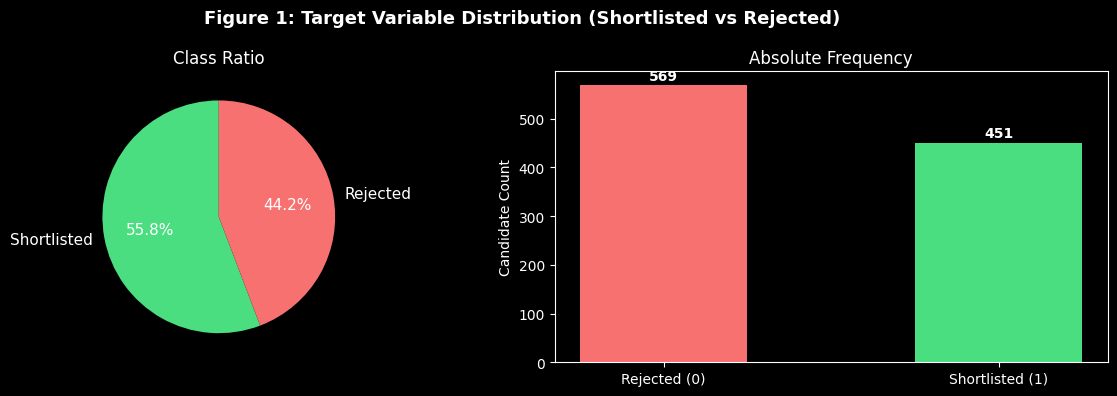

In [8]:
# Figure 1: Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Figure 1: Target Variable Distribution (Shortlisted vs Rejected)', fontsize=13, fontweight='bold', color='white')

counts = df['Shortlisted'].value_counts()
colors = ['#4ade80', '#f87171']

axes[0].pie(
    counts.values, labels=['Shortlisted', 'Rejected'],
    autopct='%1.1f%%', colors=colors, startangle=90,
    textprops={'color': 'white', 'fontsize': 11}
)
axes[0].set_title('Class Ratio', color='white')

bars = axes[1].bar(['Rejected (0)', 'Shortlisted (1)'], counts.sort_index().values, color=colors[::-1], width=0.5)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(int(bar.get_height())), ha='center', va='bottom', color='white', fontweight='bold')
axes[1].set_ylabel('Candidate Count', color='white')
axes[1].set_title('Absolute Frequency', color='white')
axes[1].tick_params(colors='white')

plt.tight_layout()
plt.show()

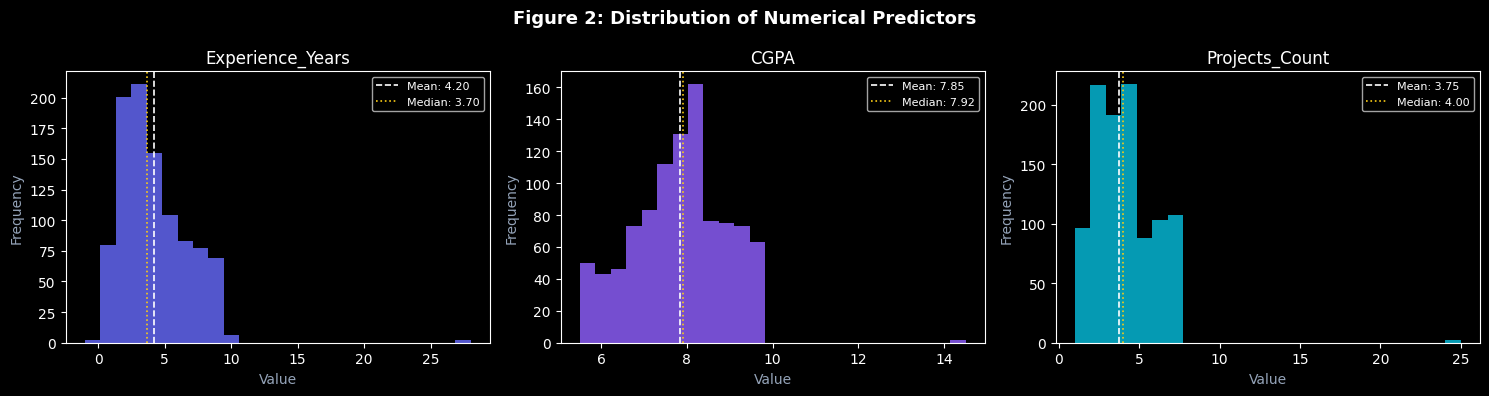

In [9]:
# Figure 2: Numerical Feature Distributions
num_cols = ['Experience_Years', 'CGPA', 'Projects_Count']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Figure 2: Distribution of Numerical Predictors', fontsize=13, fontweight='bold', color='white')
palette = ['#6366f1', '#8b5cf6', '#06b6d4']

for ax, col, color in zip(axes, num_cols, palette):
    data = df[col].dropna()
    ax.hist(data, bins=25, color=color, alpha=0.85)
    ax.axvline(data.mean(), color='white', linestyle='--', linewidth=1.2, label=f'Mean: {data.mean():.2f}')
    ax.axvline(data.median(), color='#facc15', linestyle=':', linewidth=1.2, label=f'Median: {data.median():.2f}')
    ax.set_title(col, color='white')
    ax.set_xlabel('Value', color='#94a3b8')
    ax.set_ylabel('Frequency', color='#94a3b8')
    ax.tick_params(colors='white')
    ax.legend(fontsize=8, labelcolor='white')

plt.tight_layout()
plt.show()

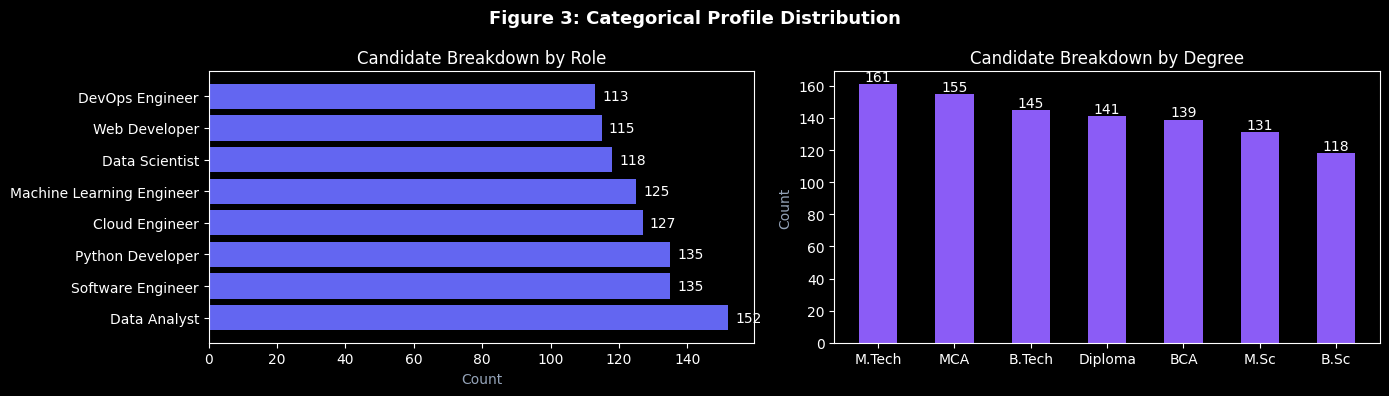

In [10]:
# Figure 3: Job Role and Education Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Figure 3: Categorical Profile Distribution', fontsize=13, fontweight='bold', color='white')

role_counts = df['Job_Role'].value_counts()
axes[0].barh(role_counts.index, role_counts.values, color='#6366f1')
for i, v in enumerate(role_counts.values):
    axes[0].text(v + 2, i, str(v), va='center', color='white', fontsize=10)
axes[0].set_title('Candidate Breakdown by Role', color='white')
axes[0].tick_params(colors='white')
axes[0].set_xlabel('Count', color='#94a3b8')

edu_counts = df['Education'].value_counts()
axes[1].bar(edu_counts.index, edu_counts.values, color='#8b5cf6', width=0.5)
for i, v in enumerate(edu_counts.values):
    axes[1].text(i, v + 2, str(v), ha='center', color='white', fontsize=10)
axes[1].set_title('Candidate Breakdown by Degree', color='white')
axes[1].tick_params(colors='white')
axes[1].set_ylabel('Count', color='#94a3b8')

plt.tight_layout()
plt.show()

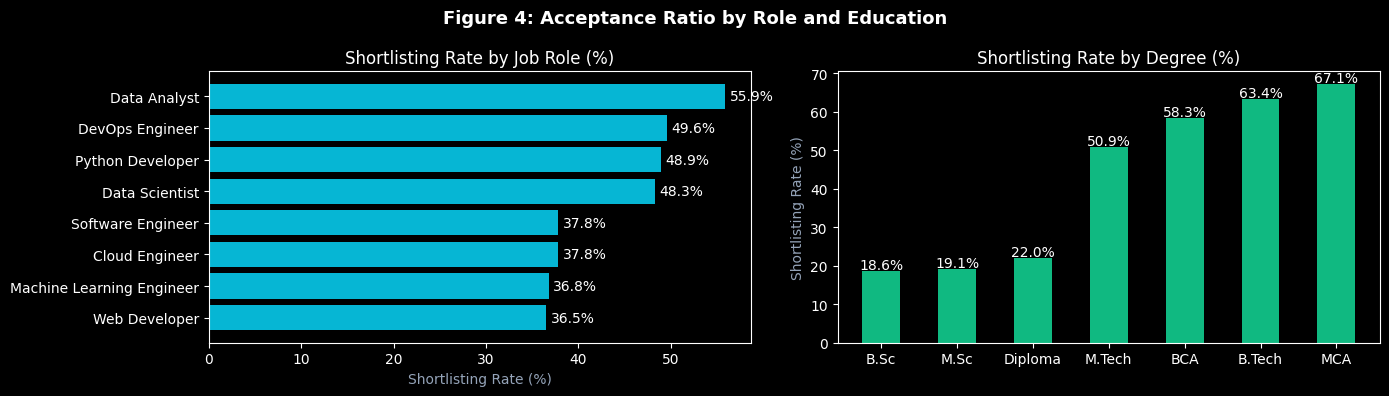

In [11]:
# Figure 4: Shortlisting Acceptance Rate by Role and Degree
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Figure 4: Acceptance Ratio by Role and Education', fontsize=13, fontweight='bold', color='white')

role_sl = df.groupby('Job_Role')['Shortlisted'].mean().mul(100).round(1).sort_values()
bars = axes[0].barh(role_sl.index, role_sl.values, color='#06b6d4')
for bar, v in zip(bars, role_sl.values):
    axes[0].text(v + 0.5, bar.get_y() + bar.get_height()/2, f'{v}%', va='center', color='white', fontsize=10)
axes[0].set_title('Shortlisting Rate by Job Role (%)', color='white')
axes[0].tick_params(colors='white')
axes[0].set_xlabel('Shortlisting Rate (%)', color='#94a3b8')

edu_sl = df.groupby('Education')['Shortlisted'].mean().mul(100).round(1).sort_values()
bars2 = axes[1].bar(edu_sl.index, edu_sl.values, color='#10b981', width=0.5)
for bar, v in zip(bars2, edu_sl.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.5, f'{v}%', ha='center', color='white', fontsize=10)
axes[1].set_title('Shortlisting Rate by Degree (%)', color='white')
axes[1].tick_params(colors='white')
axes[1].set_ylabel('Shortlisting Rate (%)', color='#94a3b8')

plt.tight_layout()
plt.show()

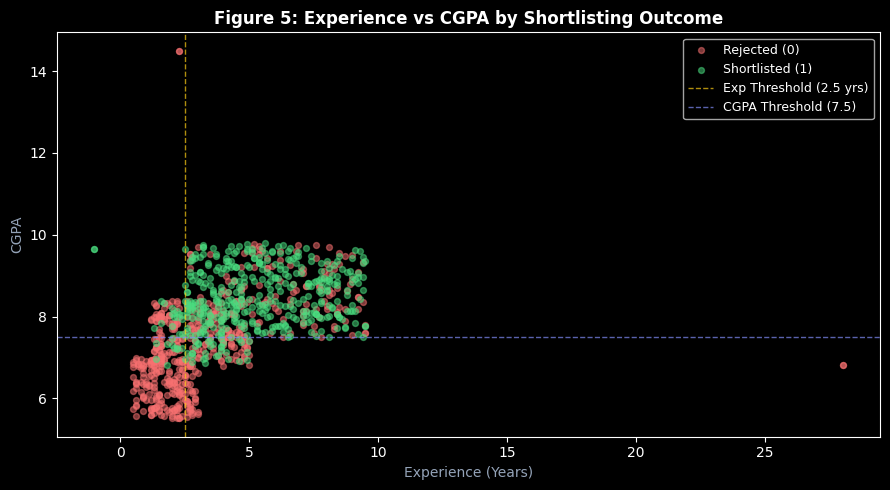

In [12]:
# Figure 5: Feature Interaction - Experience vs CGPA
fig, ax = plt.subplots(figsize=(9, 5))

sample = df.dropna(subset=['Experience_Years', 'CGPA']).copy()
shortlisted = sample[sample['Shortlisted'] == 1]
rejected    = sample[sample['Shortlisted'] == 0]

ax.scatter(rejected['Experience_Years'], rejected['CGPA'], c='#f87171', alpha=0.5, s=18, label='Rejected (0)')
ax.scatter(shortlisted['Experience_Years'], shortlisted['CGPA'], c='#4ade80', alpha=0.5, s=18, label='Shortlisted (1)')

ax.axvline(2.5, color='#facc15', linestyle='--', linewidth=1, alpha=0.7, label='Exp Threshold (2.5 yrs)')
ax.axhline(7.5, color='#818cf8', linestyle='--', linewidth=1, alpha=0.7, label='CGPA Threshold (7.5)')

ax.set_xlabel('Experience (Years)', color='#94a3b8')
ax.set_ylabel('CGPA', color='#94a3b8')
ax.set_title('Figure 5: Experience vs CGPA by Shortlisting Outcome', color='white', fontweight='bold')
ax.tick_params(colors='white')
ax.legend(fontsize=9, labelcolor='white')

plt.tight_layout()
plt.show()

## 6. Key Statistical Findings and Next Steps

In [13]:
sl_rate = df['Shortlisted'].mean() * 100
avg_exp_sl = df[df['Shortlisted']==1]['Experience_Years'].mean()
avg_exp_rej = df[df['Shortlisted']==0]['Experience_Years'].mean()
avg_cgpa_sl = df[df['Shortlisted']==1]['CGPA'].mean()
avg_cgpa_rej = df[df['Shortlisted']==0]['CGPA'].mean()

print('====================================================')
print('           WEEK 1 STATISTICAL SUMMARY')
print('====================================================')
print(f'Shortlisting Rate          : {sl_rate:.1f}%')
print(f'Avg Experience (Shortlist) : {avg_exp_sl:.2f} years vs (Rejected): {avg_exp_rej:.2f} years')
print(f'Avg CGPA (Shortlist)       : {avg_cgpa_sl:.2f} vs (Rejected): {avg_cgpa_rej:.2f}')
print(f'Missing Values Identified  : {df.isnull().sum().sum()} across 4 attributes')
print(f'Duplicate Records          : {df.duplicated().sum()}')
print('====================================================')

           WEEK 1 STATISTICAL SUMMARY
Shortlisting Rate          : 44.2%
Avg Experience (Shortlist) : 5.14 years vs (Rejected): 3.45 years
Avg CGPA (Shortlist)       : 8.42 vs (Rejected): 7.40
Missing Values Identified  : 121 across 4 attributes
Duplicate Records          : 20


### Week 1 Deliverables Summary

| Milestone Task | Status | Output Location |
|---|---|---|
| Dataset Generation Pipeline | Completed | `src/dataset_generator.py` |
| Raw Dataset Generation | Completed | `data/raw_resumes.csv` |
| Exploratory Data Analysis & Quality Audit | Completed | `notebooks/week1_data_collection_eda.ipynb` |
| Recruiter Dashboard Preview | Completed | `app.py` (Dataset Explorer) |

---

### Planned Tasks for Week 2
- Outlier detection study (IQR and Z-Score comparison).
- Missing value report and correlation matrix generation.
- Development of interactive EDA viewer in dashboard.